In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/Prathee11/unemployment_analysis/main/Unemployment%20in%20India.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [ ]:
# Dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Number of regions
print("\nNumber of Regions:")
print(df["Region"].nunique())

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB

Missing Values:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment R

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000



Number of Regions:
28

Column Names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


In [ ]:
# Remove rows with missing values
df = df.dropna().copy()

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Convert Date column into datetime format
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

print("Dataset cleaned successfully!")
print("Dataset Shape:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

display(df.head())

Dataset cleaned successfully!
Dataset Shape: (740, 7)

Missing values after cleaning:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


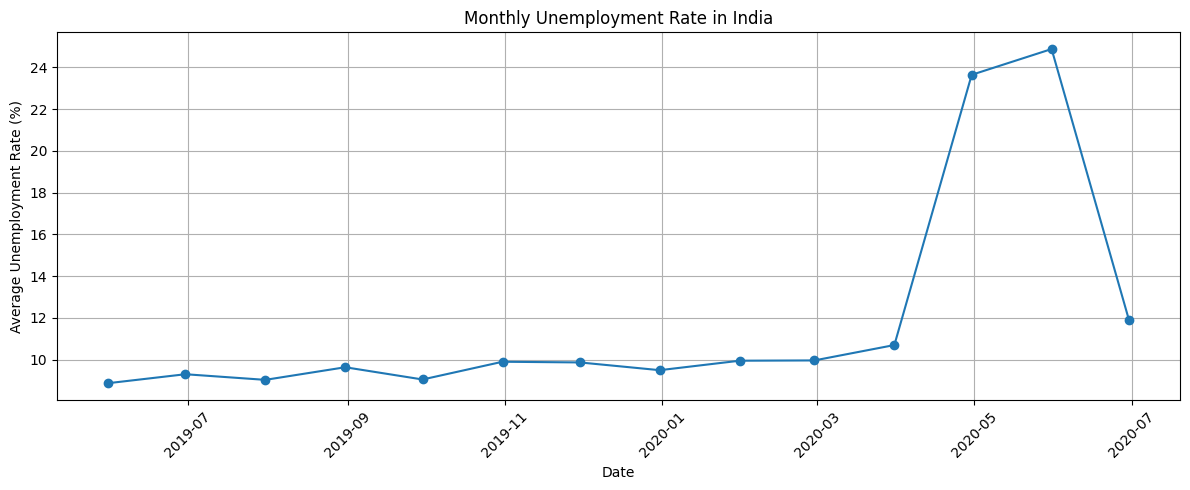

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average unemployment rate for each date
monthly_data = df.groupby("Date")[
    "Estimated Unemployment Rate (%)"
].mean().reset_index()

# Create line graph
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_data["Date"],
    monthly_data["Estimated Unemployment Rate (%)"],
    marker="o"
)

plt.title("Monthly Unemployment Rate in India")
plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

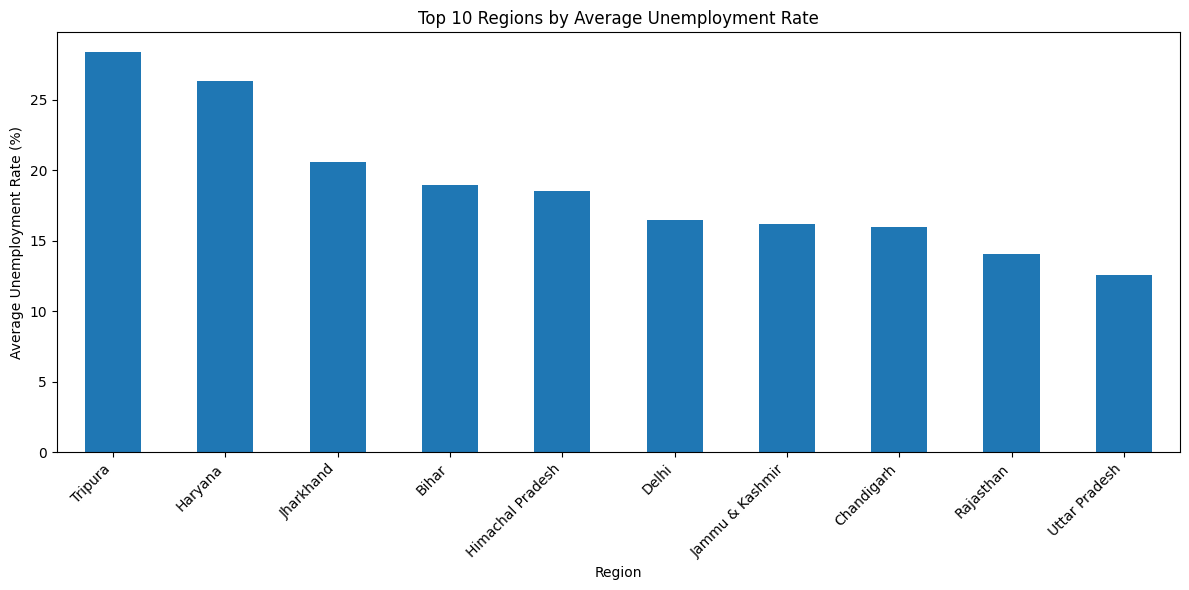

In [ ]:
# Calculate average unemployment rate by region
region_data = df.groupby("Region")[
    "Estimated Unemployment Rate (%)"
].mean().sort_values(ascending=False)

# Select top 10 regions
top_10 = region_data.head(10)

# Create bar chart
plt.figure(figsize=(12, 6))
top_10.plot(kind="bar")

plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Average Unemployment Rate Before COVID-19: 9.51 %
Average Unemployment Rate During COVID-19: 17.77 %


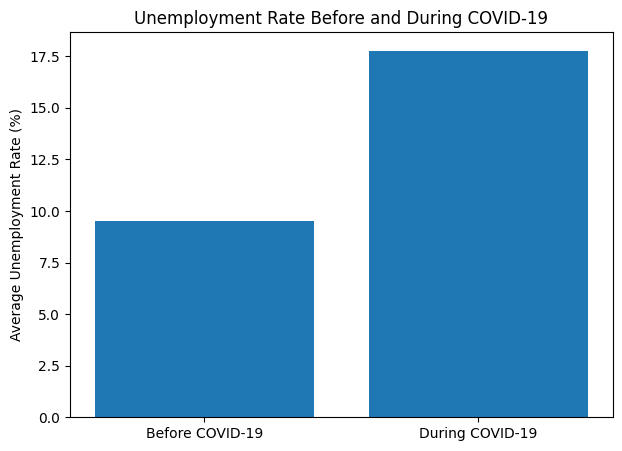

In [ ]:
# Compare unemployment rates before and during COVID-19
pre_covid = df[df["Date"] < "2020-03-01"]

during_covid = df[
    (df["Date"] >= "2020-03-01") &
    (df["Date"] <= "2020-12-31")
]

pre_rate = pre_covid["Estimated Unemployment Rate (%)"].mean()
covid_rate = during_covid["Estimated Unemployment Rate (%)"].mean()

print("Average Unemployment Rate Before COVID-19:",
      round(pre_rate, 2), "%")

print("Average Unemployment Rate During COVID-19:",
      round(covid_rate, 2), "%")

plt.figure(figsize=(7, 5))

plt.bar(
    ["Before COVID-19", "During COVID-19"],
    [pre_rate, covid_rate]
)

plt.title("Unemployment Rate Before and During COVID-19")
plt.ylabel("Average Unemployment Rate (%)")
plt.show()

In [ ]:
print("FINAL OBSERVATIONS")
print("------------------")

print("1. The dataset contains unemployment information from different regions in India.")

print("2. The line graph shows how unemployment rates change over time.")

print("3. The bar chart identifies the top 10 regions by average unemployment rate.")

print("4. The COVID-19 comparison helps examine unemployment rates before and during the pandemic.")

print("\nCONCLUSION")
print("This analysis helps us understand unemployment trends across regions and over time in India.")

FINAL OBSERVATIONS
------------------
1. The dataset contains unemployment information from different regions in India.
2. The line graph shows how unemployment rates change over time.
3. The bar chart identifies the top 10 regions by average unemployment rate.
4. The COVID-19 comparison helps examine unemployment rates before and during the pandemic.

CONCLUSION
This analysis helps us understand unemployment trends across regions and over time in India.
